# Titanic Dataset – Exploratory Data Analysis (EDA) Project

**Student Name:** _Bhagyashree Das

**Dataset Name:** Titanic - Machine Learning from Disaster

**Kaggle Dataset Link:** https://www.kaggle.com/competitions/titanic/data
**Dataset Description:** The Titanic dataset contains information about the passengers aboard the RMS Titanic, including age, sex, ticket class, fare, and whether they survived the sinking.


**Objective of the Analysis:** To explore, clean, and analyze the Titanic dataset in order to understand the factors that influenced passenger survival, and to prepare a clean dataset suitable for future machine-learning work.


## 2. Load the Dataset

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
%matplotlib inline

In [2]:
# Load the dataset directly from a public mirror of the Kaggle Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
print("Dataset loaded successfully. Shape:", df.shape)

Dataset loaded successfully. Shape: (891, 12)


In [3]:
# Display first and last few records
display(df.head())
display(df.tail())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


## 3. Understand the Dataset

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:\n", df.columns.tolist())

Number of rows: 891
Number of columns: 12

Column names:
 ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [7]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

PassengerId: 891 unique values
Survived: 2 unique values
Pclass: 3 unique values
Name: 891 unique values
Sex: 2 unique values
Age: 88 unique values
SibSp: 7 unique values
Parch: 7 unique values
Ticket: 681 unique values
Fare: 248 unique values
Cabin: 147 unique values
Embarked: 3 unique values


**Observation:** The dataset has both numerical columns (e.g. `Age`, `Fare`) and categorical columns (e.g. `Sex`, `Embarked`, `Pclass`). Some columns such as `Cabin` and `Age` appear to have missing values, and `Name`/`Ticket` are high-cardinality text fields that will need special handling.

## 4. Check and Remove Duplicate Records

In [8]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows found:", duplicate_count)

shape_before = df.shape
df = df.drop_duplicates()
shape_after = df.shape

print("Shape before removing duplicates:", shape_before)
print("Shape after removing duplicates:", shape_after)

Number of duplicate rows found: 0
Shape before removing duplicates: (891, 12)
Shape after removing duplicates: (891, 12)


## 5. Handle Missing Values

In [9]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct.round(2)}).sort_values("Missing Count", ascending=False)

,Missing Count,Missing %
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [10]:
# Age: fill with median (robust to outliers)
df['Age'] = df['Age'].fillna(df['Age'].median())

# Embarked: fill with mode (most frequent port)
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Cabin: too many missing values to impute meaningfully -> drop the column
df = df.drop(columns=['Cabin'])

print("Missing values after handling:\n", df.isnull().sum())

Missing values after handling:
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


**Reason for approach:** `Age` was filled with the median because it is numerical and the median is not skewed by outliers. `Embarked` was filled with the mode since it is categorical with very few missing values. `Cabin` had too many missing values (~77%) to impute reliably, so it was dropped.

## 6. Clean the Dataset

In [11]:
# Correct data types
df['Pclass'] = df['Pclass'].astype('category')
df['Survived'] = df['Survived'].astype('category')
df['Sex'] = df['Sex'].str.strip().str.lower()
df['Embarked'] = df['Embarked'].str.strip().str.upper()

# Remove unnecessary columns (identifiers not useful for analysis)
df_clean = df.drop(columns=['PassengerId', 'Name', 'Ticket'])

df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 7. Analyze Categorical Columns

In [12]:
categorical_cols = ['Survived', 'Pclass', 'Sex', 'Embarked']
for col in categorical_cols:
    print(f"\n{col} value counts:")
    print(df_clean[col].value_counts())


Survived value counts:
Survived
0    549
1    342
Name: count, dtype: int64

Pclass value counts:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Sex value counts:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked value counts:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


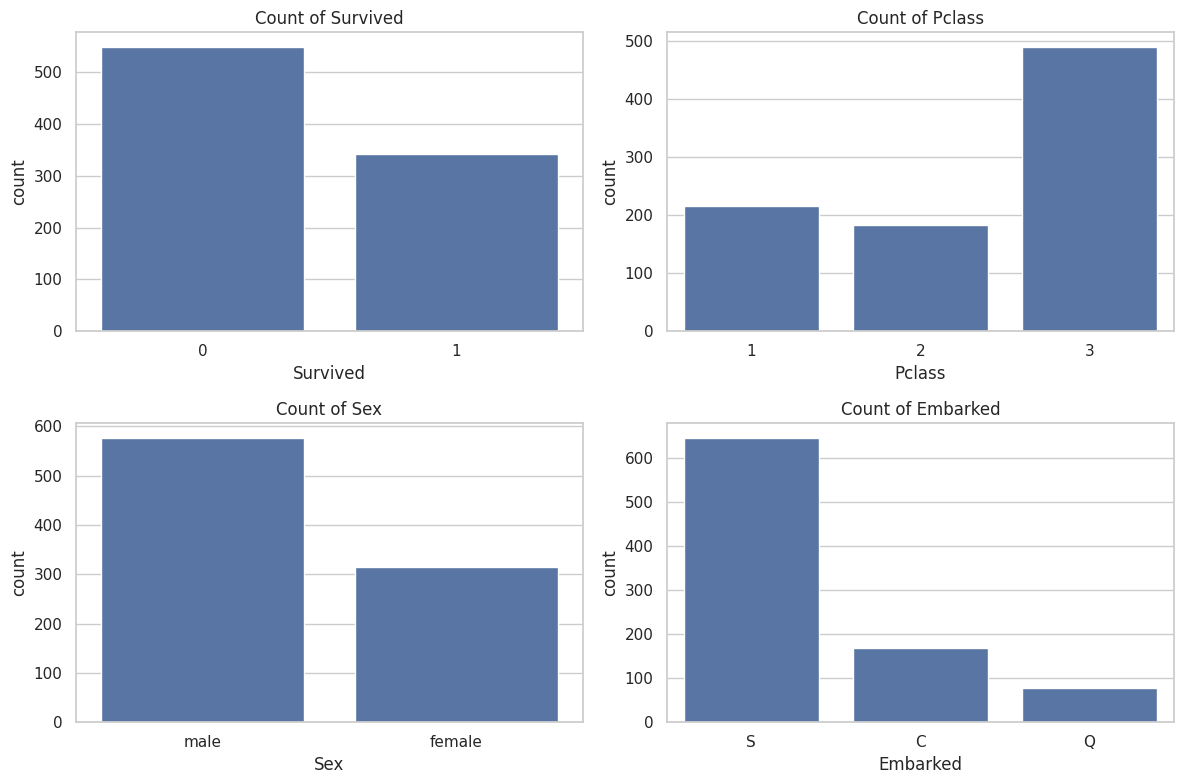

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), categorical_cols):
    sns.countplot(x=col, data=df_clean, ax=ax)
    ax.set_title(f'Count of {col}')
plt.tight_layout()
plt.show()

**Observation:** More passengers did not survive than survived. There were more male passengers than female, most passengers traveled in 3rd class, and most boarded from Southampton (S).

## 8. Analyze Numerical Columns

In [14]:
numerical_cols = ['Age', 'Fare', 'SibSp', 'Parch']
df_clean[numerical_cols].agg(['mean', 'median', 'min', 'max', 'std']).T

,mean,median,min,max,std
Age,29.361582,28.0000,0.42,80.0000,13.019697
Fare,32.204208,14.4542,0.00,512.3292,49.693429
SibSp,0.523008,0.0000,0.00,8.0000,1.102743
Parch,0.381594,0.0000,0.00,6.0000,0.806057


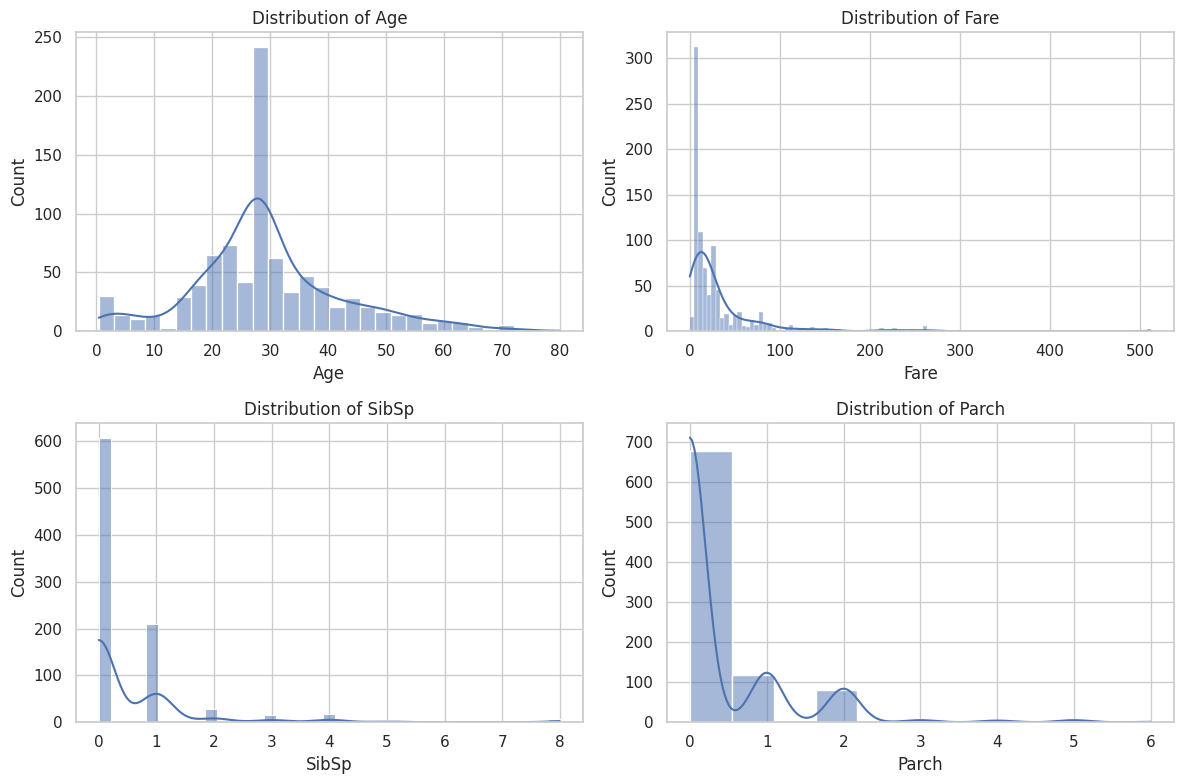

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), numerical_cols):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

**Observation:** `Age` is roughly centered around 28-30 years. `Fare` is heavily right-skewed, with most fares low and a few very high-paying passengers. `SibSp` and `Parch` are mostly 0, meaning most passengers traveled without immediate family.

## 9. Detect and Handle Outliers

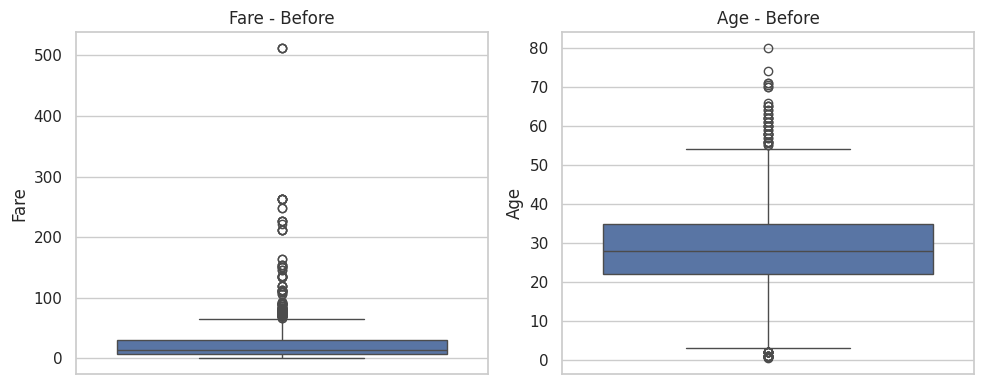

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df_clean['Fare'], ax=axes[0])
axes[0].set_title('Fare - Before')
sns.boxplot(y=df_clean['Age'], ax=axes[1])
axes[1].set_title('Age - Before')
plt.tight_layout()
plt.show()

In [17]:
# Cap extreme Fare values using the IQR method (capping instead of removing, to preserve data)
Q1 = df_clean['Fare'].quantile(0.25)
Q3 = df_clean['Fare'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

before_count = (df_clean['Fare'] > upper_limit).sum()
df_clean['Fare'] = np.where(df_clean['Fare'] > upper_limit, upper_limit, df_clean['Fare'])
print(f"Number of Fare outliers capped: {before_count}")

Number of Fare outliers capped: 116


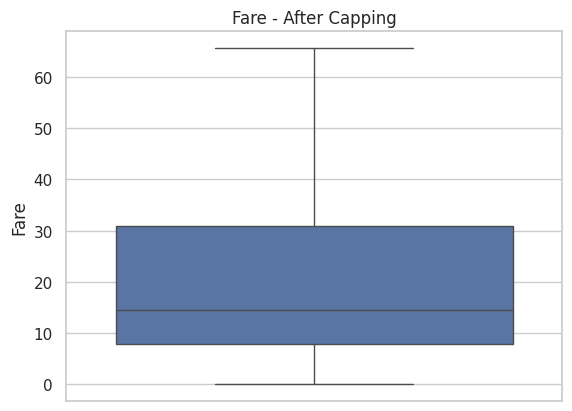

In [18]:
sns.boxplot(y=df_clean['Fare'])
plt.title('Fare - After Capping')
plt.show()

**Explanation:** `Fare` outliers were capped (not removed) using the IQR method, because a few passengers legitimately paid very high fares (first-class suites) and removing them would lose real information. `Age` outliers were left as-is since ages up to ~80 are realistic and not data errors.

## 10. Perform Univariate Analysis

Age - min: 0.42 max: 80.0
Most common Pclass: 3
Most common Embarked port: S


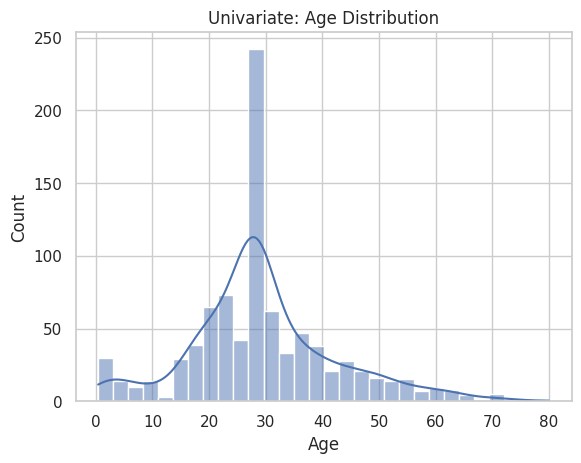

In [19]:
print("Age - min:", df_clean['Age'].min(), "max:", df_clean['Age'].max())
print("Most common Pclass:", df_clean['Pclass'].mode()[0])
print("Most common Embarked port:", df_clean['Embarked'].mode()[0])
sns.histplot(df_clean['Age'], bins=30, kde=True)
plt.title('Univariate: Age Distribution')
plt.show()

## 11. Perform Bivariate Analysis

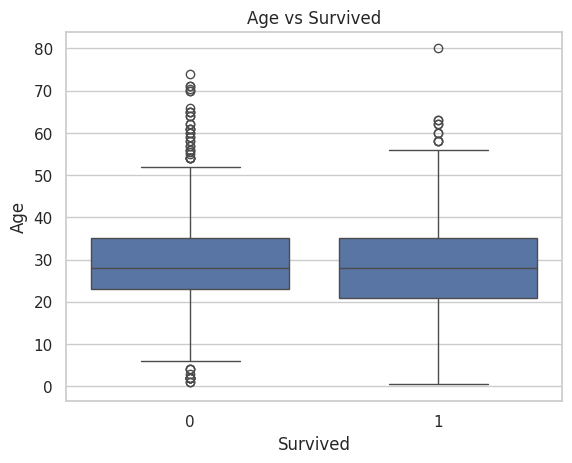

In [20]:
# Numerical vs Categorical: Age vs Survived
sns.boxplot(x='Survived', y='Age', data=df_clean)
plt.title('Age vs Survived')
plt.show()

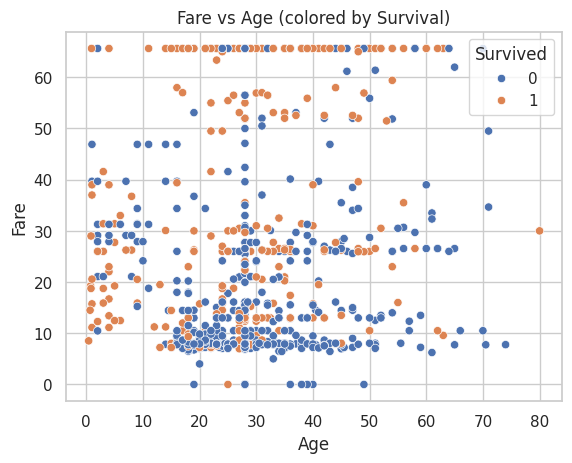

In [21]:
# Numerical vs Numerical: Fare vs Age
sns.scatterplot(x='Age', y='Fare', hue='Survived', data=df_clean)
plt.title('Fare vs Age (colored by Survival)')
plt.show()

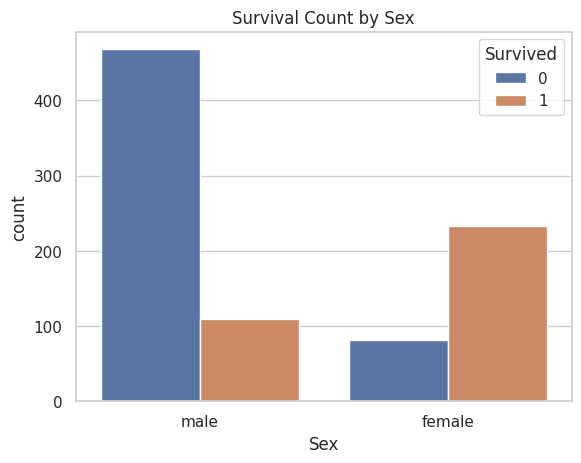

In [22]:
# Categorical vs Categorical: Sex vs Survived
sns.countplot(x='Sex', hue='Survived', data=df_clean)
plt.title('Survival Count by Sex')
plt.show()

**Observation:** Females had a much higher survival rate than males. Younger passengers show a slightly higher survival tendency, and higher fares are loosely associated with survival.

## 12. Perform Multivariate Analysis

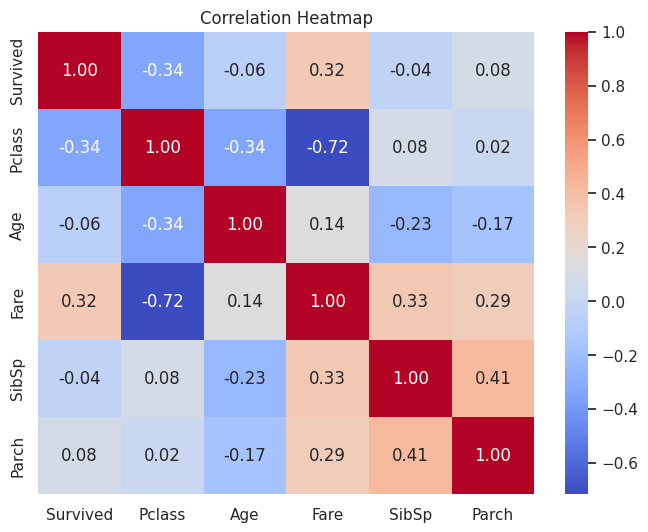

In [23]:
corr_df = df_clean.copy()
corr_df['Survived'] = corr_df['Survived'].astype(int)
corr_df['Pclass'] = corr_df['Pclass'].astype(int)
corr = corr_df[['Survived', 'Pclass', 'Age', 'Fare', 'SibSp', 'Parch']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

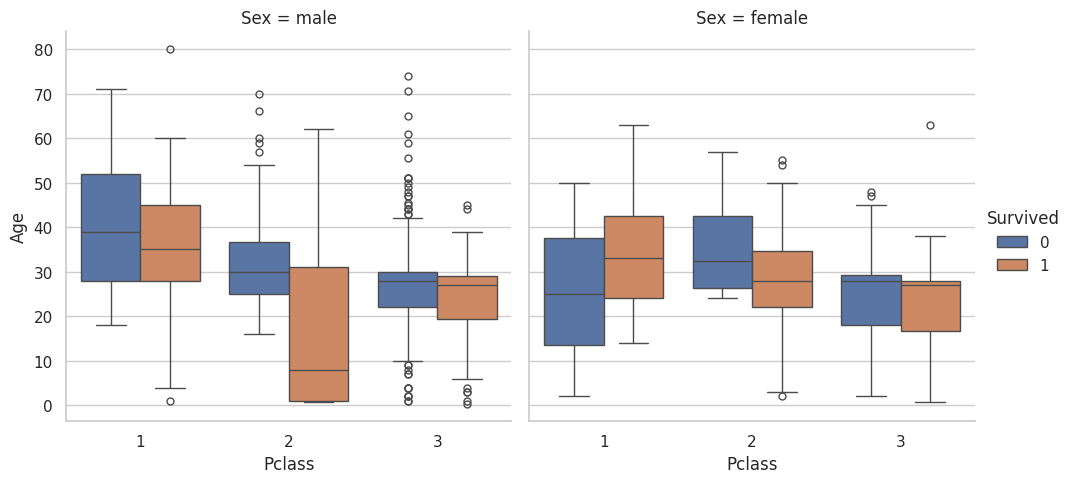

In [24]:
sns.catplot(x='Pclass', y='Age', hue='Survived', col='Sex', kind='box', data=df_clean)
plt.show()

**Observation:** `Pclass` and `Fare` show a meaningful correlation with `Survived` — higher class and higher fare are associated with better survival odds. Combining `Sex` and `Pclass` shows that female passengers in 1st and 2nd class had the highest survival rates.

## 13. Key Insights

1. Overall survival rate was low — the majority of passengers did not survive.
2. Sex was the strongest predictor of survival: females survived at a much higher rate than males.
3. Passenger class (`Pclass`) strongly correlates with survival — 1st class passengers survived more often than 3rd class.
4. Fare is right-skewed; a small number of passengers paid very high fares, mostly in 1st class.
5. Age is fairly evenly distributed but children show a slightly higher survival rate than adults.
6. Most passengers traveled alone (`SibSp` and `Parch` mostly 0).
7. Most passengers embarked from Southampton (S), and embarkation port shows a mild relationship with class and fare.
8. `Cabin` had too much missing data to be useful without heavy assumptions, so it was dropped.
9. Combining `Sex` and `Pclass` reveals the highest survival rates belonged to female, 1st-class passengers.
10. After cleaning, the dataset is well-suited for building a binary classification model to predict `Survived`.

## 14. Final Conclusion

This EDA project explored the Titanic dataset to understand what factors influenced passenger survival. After cleaning missing values, correcting data types, and handling outliers in `Fare`, clear patterns emerged: **sex, passenger class, and fare** were the strongest indicators of survival, while age played a smaller but still noticeable role.

**Major data-quality issues found:** significant missing values in `Age` and `Cabin`, a right-skewed `Fare` distribution with high-value outliers, and inconsistent text casing in categorical columns.

**Usefulness for future ML projects:** The cleaned dataset (`df_clean`) is now ready to be used as input for a classification model (e.g., logistic regression, decision tree, or random forest) to predict passenger survival, with `Survived` as the target variable.

## Final Cleaned Dataset

In [25]:
print("Final cleaned dataset shape:", df_clean.shape)
df_clean.head()

Final cleaned dataset shape: (891, 8)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,65.6344,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [26]:
# Save the cleaned dataset (optional, for submission)
df_clean.to_csv("titanic_clean.csv", index=False)
print("Saved cleaned dataset as titanic_clean.csv")

Saved cleaned dataset as titanic_clean.csv
